In [3]:
import pandas as pd

file_path = r"J:\python\Codesoft_Data _Analysis/Online Retail.xlsx"

df = pd.read_excel(file_path)

print(df.shape)
display(df.head())

(541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [4]:
# 1. Check the number of rows and columns
print("Dataset shape:", df.shape)

# 2. View all column names
print("\nColumn names:")
print(df.columns.tolist())

# 3. Check column data types
print("\nDataset information:")
df.info()

# 4. Check missing values
print("\nMissing values in each column:")
display(df.isnull().sum())

# 5. Check duplicate records
print("\nNumber of duplicate rows:", df.duplicated().sum())

# 6. View basic statistical information
display(df.describe(include="all").T)

Dataset shape: (541909, 8)

Column names:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 33.1+ MB

Missing values in each column:


InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64


Number of duplicate rows: 5268


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
InvoiceNo,541909.0,25900.0,573585.0,1114.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
StockCode,541909,4070,85123A,2313,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Description,540455,4223,WHITE HANGING HEART T-LIGHT HOLDER,2369,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Quantity,541909.0,NaN,NaN,NaN,9.55225,-80995.0,1.0,3.0,10.0,80995.0,218.081158
InvoiceDate,541909,NaN,NaN,NaN,2011-07-04 13:34:57.156386,2010-12-01 08:26:00,2011-03-28 11:34:00,2011-07-19 17:17:00,2011-10-19 11:27:00,2011-12-09 12:50:00,NaN
UnitPrice,541909.0,NaN,NaN,NaN,4.611114,-11062.06,1.25,2.08,4.13,38970.0,96.759853
CustomerID,406829.0,NaN,NaN,NaN,15287.69057,12346.0,13953.0,15152.0,16791.0,18287.0,1713.600303
Country,541909,38,United Kingdom,495478,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [6]:
# Calculate missing values in each column
missing_values = df.isnull().sum()

# Calculate missing-value percentage
missing_percentage = (missing_values / len(df)) * 100

# Create a summary table
missing_summary = pd.DataFrame({
    "Missing Values": missing_values,
    "Missing Percentage": missing_percentage.round(2)
})

display(missing_summary)


,Missing Values,Missing Percentage
InvoiceNo,0,0.00
StockCode,0,0.00
Description,1454,0.27
Quantity,0,0.00
InvoiceDate,0,0.00
UnitPrice,0,0.00
CustomerID,135080,24.93
Country,0,0.00


In [7]:
# Keep an original copy
df_original = df.copy()

# Remove rows without CustomerID
df = df.dropna(subset=["CustomerID"]).copy()

print("Shape before cleaning:", df_original.shape)
print("Shape after removing missing CustomerID:", df.shape)
print("\nMissing values after cleaning:")
display(df.isnull().sum())

Shape before cleaning: (541909, 8)
Shape after removing missing CustomerID: (406829, 8)

Missing values after cleaning:


InvoiceNo      0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
UnitPrice      0
CustomerID     0
Country        0
dtype: int64

In [8]:
# Check duplicate records
print("Duplicate rows before cleaning:", df.duplicated().sum())

# Remove duplicate records
df = df.drop_duplicates().copy()

# Check the updated dataset
print("Dataset shape after removing duplicates:", df.shape)
print("Duplicate rows after cleaning:", df.duplicated().sum())

Duplicate rows before cleaning: 5225
Dataset shape after removing duplicates: (401604, 8)
Duplicate rows after cleaning: 0


In [9]:
# Check negative quantities
print("Negative quantities:", (df["Quantity"] < 0).sum())

# Check zero quantities
print("Zero quantities:", (df["Quantity"] == 0).sum())

# Check zero or negative prices
print("Zero or negative prices:", (df["UnitPrice"] <= 0).sum())

# Check cancelled invoices
print(
    "Cancelled invoices:",
    df["InvoiceNo"].astype(str).str.startswith("C").sum()
)

Negative quantities: 8872
Zero quantities: 0
Zero or negative prices: 40
Cancelled invoices: 8872


In [11]:
# Create a separate dataset for sales analysis
sales_df = df[
    (df["Quantity"] > 0) &
    (df["UnitPrice"] > 0) &
    (~df["InvoiceNo"].astype(str).str.startswith("C"))
].copy()

print("Rows before sales filtering:", len(df))
print("Rows after sales filtering:", len(sales_df))
print("Negative quantities remaining:", (sales_df["Quantity"] < 0).sum())
print("Invalid prices remaining:", (sales_df["UnitPrice"] <= 0).sum())

Rows before sales filtering: 401604
Rows after sales filtering: 392692
Negative quantities remaining: 0
Invalid prices remaining: 0


In [12]:
# Calculate revenue for each transaction line
sales_df["Revenue"] = sales_df["Quantity"] * sales_df["UnitPrice"]

print("Total sales revenue:", round(sales_df["Revenue"].sum(), 2))
display(sales_df.head())

Total sales revenue: 8887208.89


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34


In [13]:
# Top 10 products by revenue
top_products = (
    sales_df.groupby("Description")["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
)

display(top_products)

,Description,Revenue
0,"PAPER CRAFT , LITTLE BIRDIE",168469.60
1,REGENCY CAKESTAND 3 TIER,142264.75
2,WHITE HANGING HEART T-LIGHT HOLDER,100392.10
3,JUMBO BAG RED RETROSPOT,85040.54
4,MEDIUM CERAMIC TOP STORAGE JAR,81416.73
5,POSTAGE,77803.96
6,PARTY BUNTING,68785.23
7,ASSORTED COLOUR BIRD ORNAMENT,56413.03
8,Manual,53419.93
9,RABBIT NIGHT LIGHT,51251.24


In [14]:
# Top 10 countries by revenue
top_countries = (
    sales_df.groupby("Country")["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
)

display(top_countries)

,Country,Revenue
0,United Kingdom,7285024.644
1,Netherlands,285446.340
2,EIRE,265262.460
3,Germany,228678.400
4,France,208934.310
5,Australia,138453.810
6,Spain,61558.560
7,Switzerland,56443.950
8,Belgium,41196.340
9,Sweden,38367.830


In [15]:
# Extract year and month from InvoiceDate
sales_df["InvoiceDate"] = pd.to_datetime(sales_df["InvoiceDate"])

sales_df["YearMonth"] = sales_df["InvoiceDate"].dt.to_period("M")

# Calculate monthly revenue
monthly_sales = (
    sales_df.groupby("YearMonth")["Revenue"]
    .sum()
    .reset_index()
)

monthly_sales["YearMonth"] = monthly_sales["YearMonth"].astype(str)

display(monthly_sales)

,YearMonth,Revenue
0,2010-12,570422.730
1,2011-01,568101.310
2,2011-02,446084.920
3,2011-03,594081.760
4,2011-04,468374.331
5,2011-05,677355.150
6,2011-06,660046.050
7,2011-07,598962.901
8,2011-08,644051.040
9,2011-09,950690.202


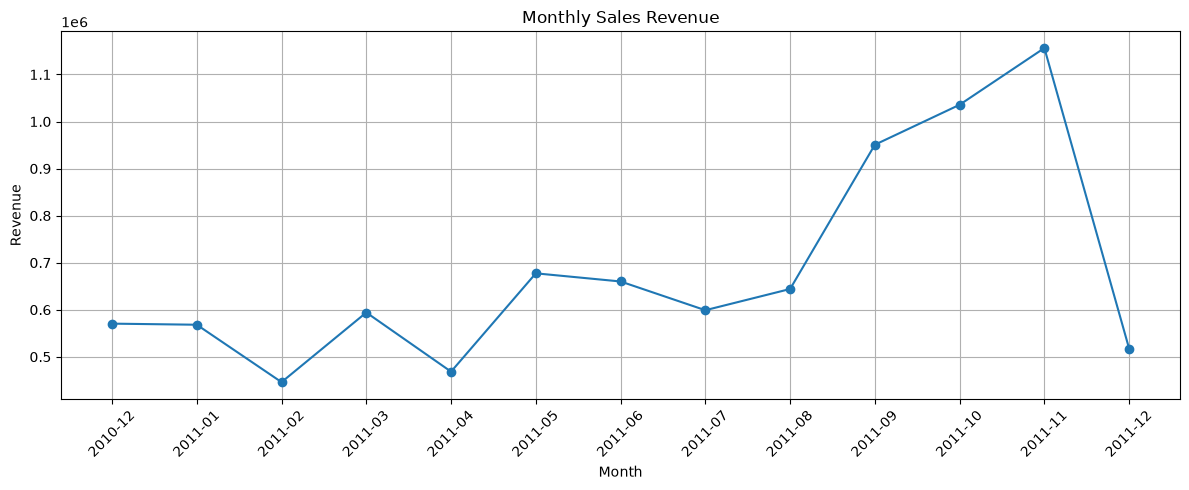

In [21]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.plot(
    monthly_sales["YearMonth"],
    monthly_sales["Revenue"],
    marker="o"
)

plt.title("Monthly Sales Revenue")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.savefig("monthly_sales.png", dpi=300, bbox_inches="tight")
plt.show()


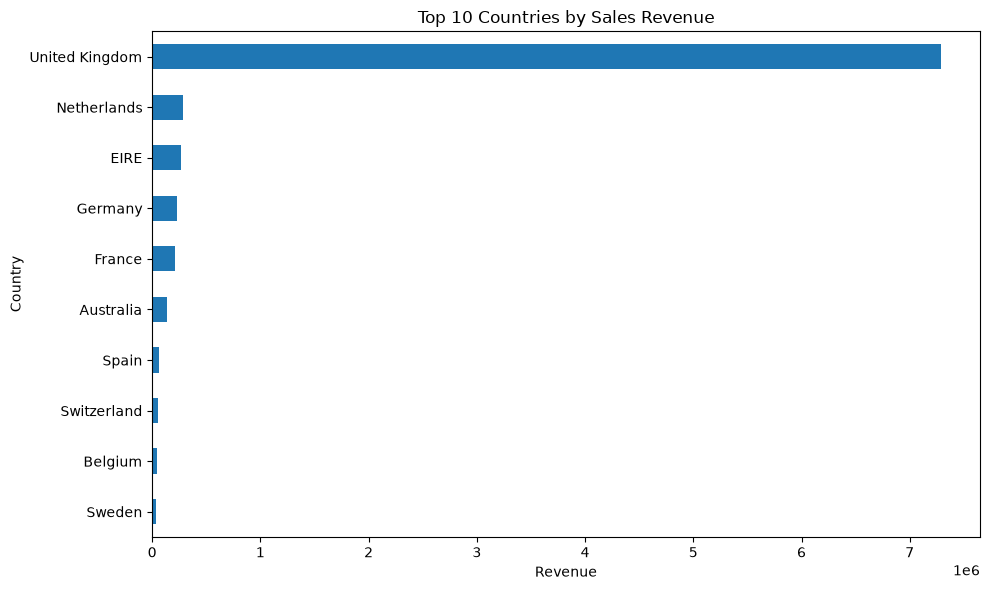

In [22]:
top_countries = (
    sales_df.groupby("Country")["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .sort_values()
)

plt.figure(figsize=(10, 6))

top_countries.plot(kind="barh")

plt.title("Top 10 Countries by Sales Revenue")
plt.xlabel("Revenue")
plt.ylabel("Country")
plt.tight_layout()
plt.savefig("top_10_countries.png", dpi=300, bbox_inches="tight")
plt.show()

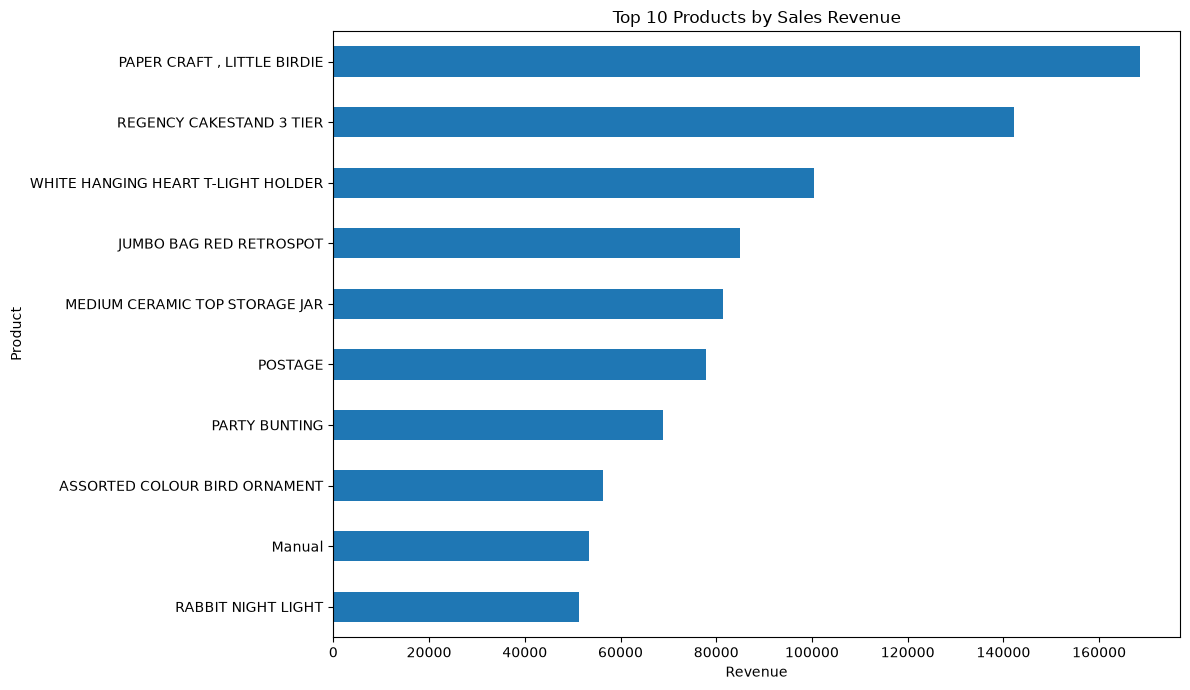

In [23]:
# Find the top 10 products by revenue
top_products = (
    sales_df.groupby("Description")["Revenue"]
    .sum()
    .nlargest(10)
    .sort_values()
)

# Create a horizontal bar chart
plt.figure(figsize=(12, 7))
top_products.plot(kind="barh")

plt.title("Top 10 Products by Sales Revenue")
plt.xlabel("Revenue")
plt.ylabel("Product")
plt.tight_layout()
plt.savefig("top_10_products.png", dpi=300, bbox_inches="tight")
plt.show()

In [24]:
# Save the cleaned sales data
sales_df.to_csv("Online_Retail_Cleaned.csv", index=False)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


In [25]:
print("Total transactions:", sales_df["InvoiceNo"].nunique())
print("Total products sold:", sales_df["Quantity"].sum())
print("Total revenue:", round(sales_df["Revenue"].sum(), 2))
print("Number of countries:", sales_df["Country"].nunique())
print("Number of customers:", sales_df["CustomerID"].nunique())

Total transactions: 18532
Total products sold: 5152002
Total revenue: 8887208.89
Number of countries: 37
Number of customers: 4338


In [26]:
readme_text = """# Online Retail Data Analysis

## Project Overview
This project analyzes online retail transactions using Python to understand sales performance, product revenue, and monthly sales trends.

## Tools Used
- Python
- Pandas
- Matplotlib
- Jupyter Notebook

## Data Cleaning
- Checked missing values and data types.
- Removed rows with missing CustomerID.
- Removed duplicate records.
- Filtered non-positive quantities and prices for sales analysis.
- Calculated revenue using Quantity multiplied by UnitPrice.

## Key Results
- Sales transactions: 18,532
- Total quantity sold: 5,152,002
- Total revenue: 8,887,208.89
- Countries represented: 37
- Unique customers: 4,338

## Visualizations
1. Monthly Sales Revenue
2. Top 10 Countries by Sales Revenue
3. Top 10 Products by Sales Revenue

## Conclusion
This project demonstrates data cleaning, exploratory data analysis, and visualization using Python.
"""

with open("README.md", "w", encoding="utf-8") as file:
    file.write(readme_text)

print("README.md created successfully!")

README.md created successfully!
